# Week 9: Collaboration Analytics

Eight groups of four or five undergraduates working in a chat over four days, and 39 pairs of children working at two screens with a robot.

In [1]:
%matplotlib inline
import pandas as pd, numpy as np, matplotlib.pyplot as plt, warnings
from scipy import stats
warnings.filterwarnings("ignore")

BASE = "https://raw.githubusercontent.com/HakeoungLee/edis8100-datasets/main"
OKABE = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "red": "#D55E00",
         "purple": "#CC79A7", "sky": "#56B4E9", "grey": "#666666"}
MEMBER_COLORS = [OKABE["blue"], OKABE["orange"], OKABE["green"], OKABE["purple"], OKABE["sky"]]
pd.set_option("display.width", 120)

chat = pd.read_csv(f"{BASE}/collab-chat/chat_logs_en.csv")
chat = chat.rename(columns={"group": "Group", "author": "authorid", "message": "message"})
chat["ts"] = pd.to_datetime(chat["timestamp"], format="%d/%m/%Y %H:%M")
chat["day"] = chat["ts"].dt.date
chat["session"] = chat["Group"].astype(str) + " / " + chat["day"].astype(str)
chat = chat.sort_values(["Group", "ts"]).reset_index(drop=True)

print(f"{len(chat):,} messages | {chat.Group.nunique()} groups | {chat.authorid.nunique()} people")
display(chat[["Group", "authorid", "message"]].head(6))

1,374 messages | 8 groups | 34 people


,Group,authorid,message
0,1,a.7jKzKFsPBtn1hT5G,hi chat
1,1,a.DiXDQxpPWP7gz4LT,hi group
2,1,a.I6ZFAmhSZ4KY2HU1,Hiii
3,1,a.7jKzKFsPBtn1hT5G,hi
4,1,a.DiXDQxpPWP7gz4LT,Okay we have quite a few questions that are ne...
5,1,a.7jKzKFsPBtn1hT5G,we have a couple of the video on demand one


## 1. Equality of participation

Equality of participation is the most common indicator in collaboration analytics. The figure reports each group's recorded messages divided among its members, ordered from the member with the most to the member with the fewest. The vertical marks give the even split.

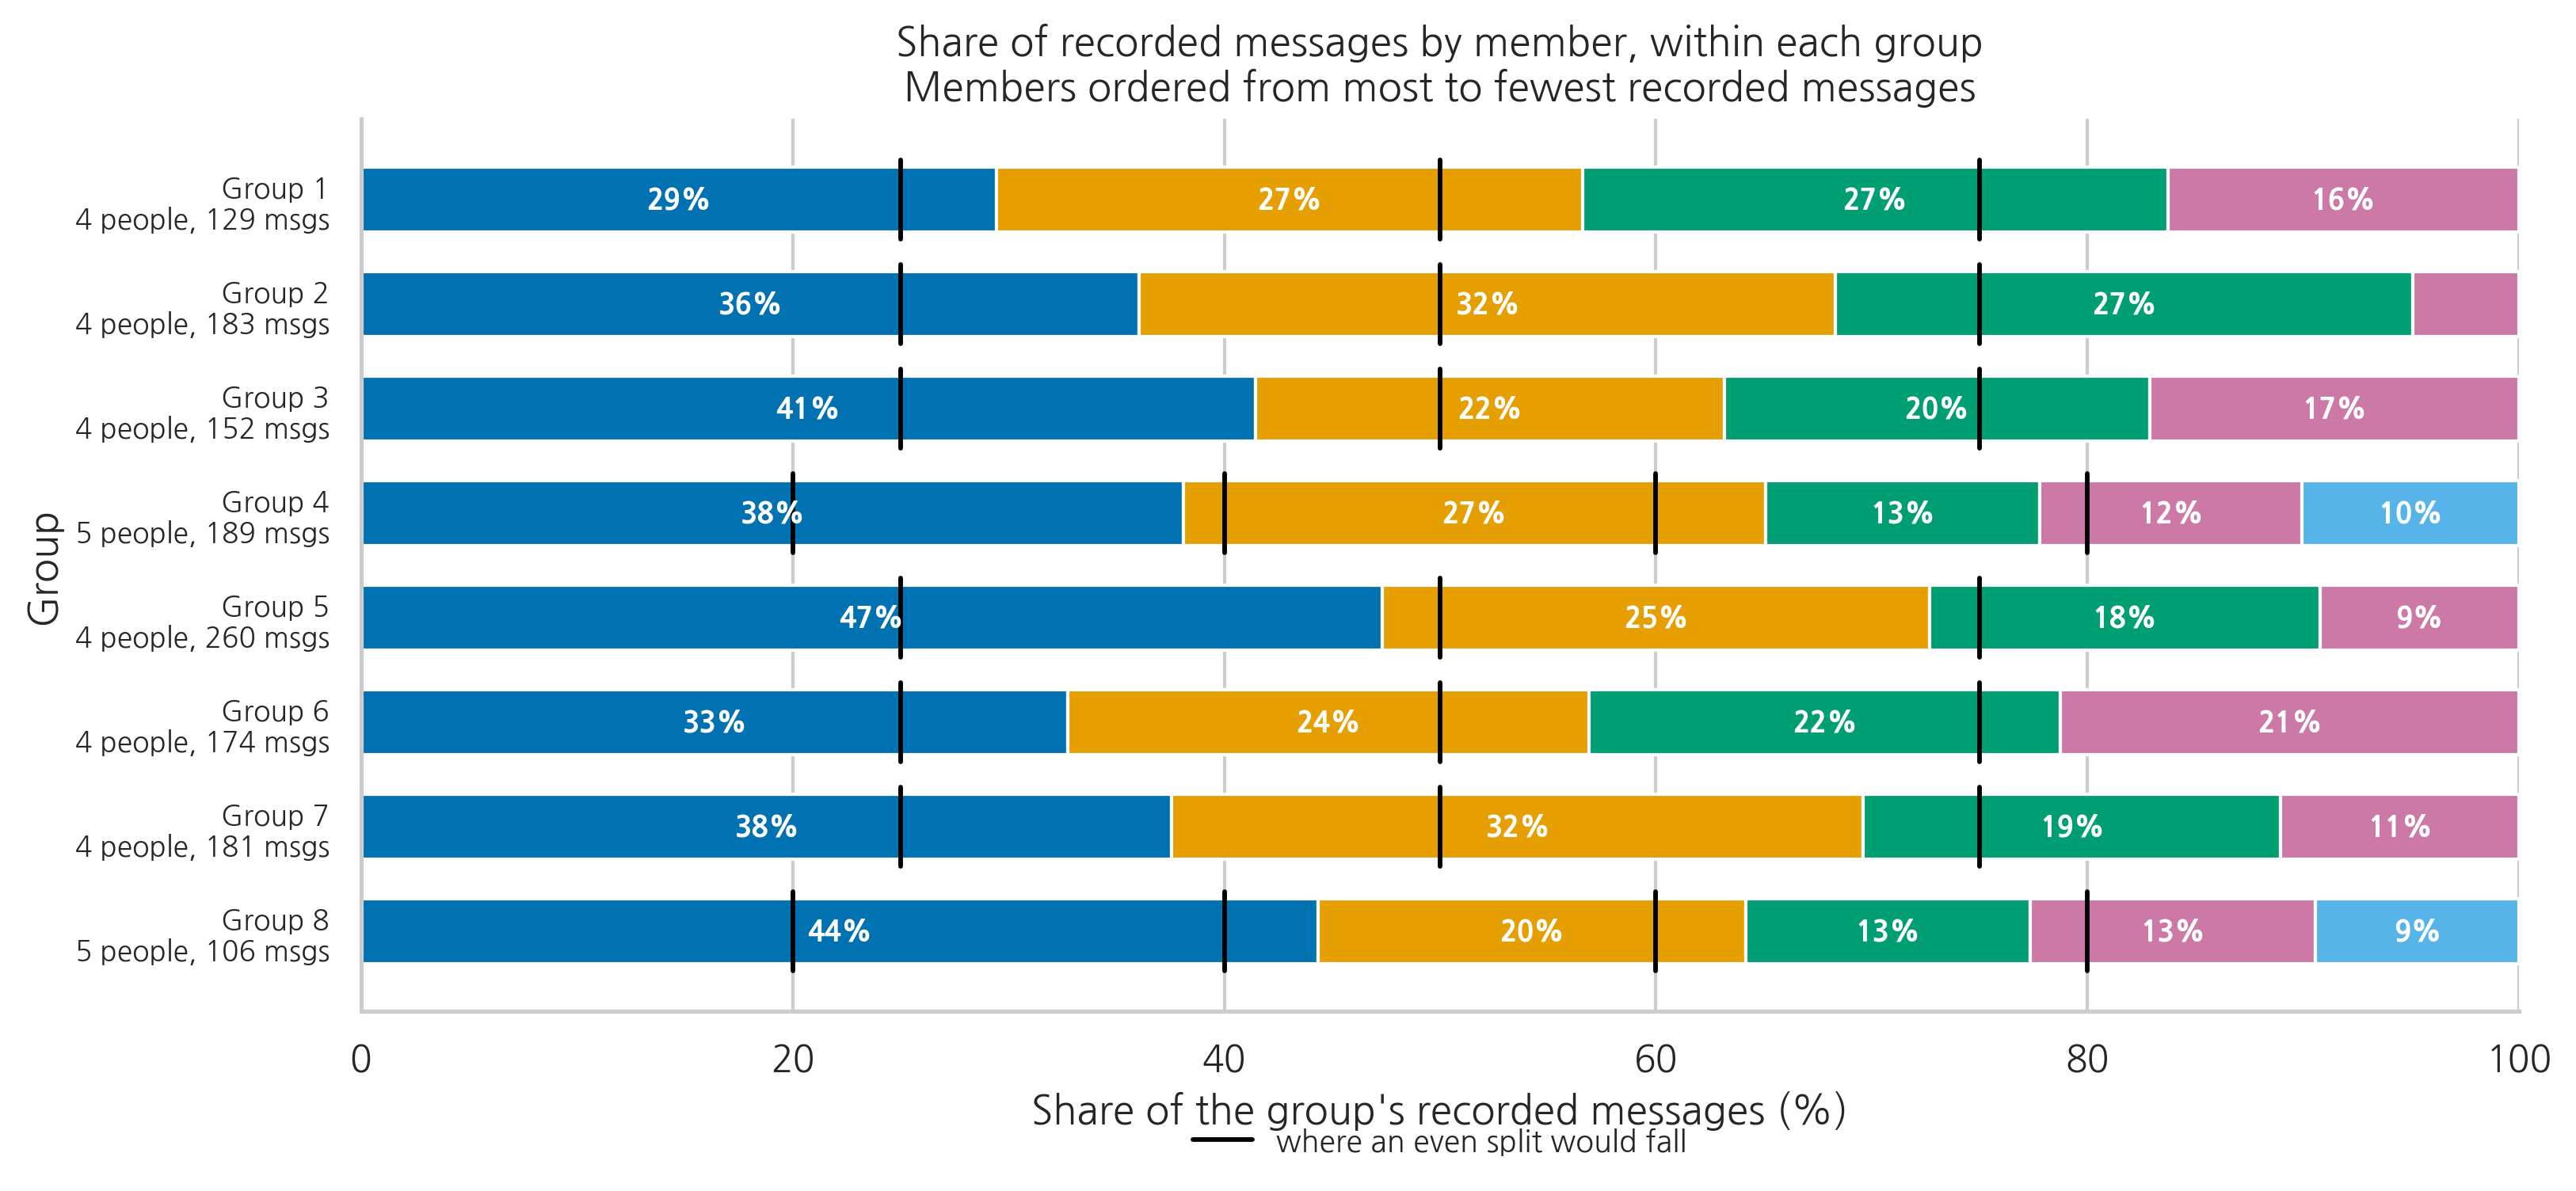

In [2]:
fig, ax = plt.subplots(figsize=(11, 5.2))
ylabels = []
for i, g in enumerate(sorted(chat["Group"].unique())):
    counts = chat[chat["Group"] == g]["authorid"].value_counts().sort_values(ascending=False)
    total = counts.sum()
    left = 0.0
    for j, (_a, c) in enumerate(counts.items()):
        w = 100 * c / total
        ax.barh(i, w, left=left, color=MEMBER_COLORS[j], edgecolor="white", height=0.62)
        if w > 6:
            ax.text(left + w / 2, i, f"{w:.0f}%", ha="center", va="center",
                    fontsize=8.5, color="white", fontweight="bold")
        left += w
    n = len(counts)
    for k in range(1, n):
        ax.plot([100 * k / n] * 2, [i - 0.38, i + 0.38], color="black", linewidth=1.4)
    ylabels.append(f"Group {g}\n{n} people, {total} msgs")
ax.plot([], [], color="black", linewidth=1.4, label="where an even split would fall")
ax.set_yticks(range(len(ylabels)))
ax.set_yticklabels(ylabels, fontsize=8.5)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of the group's recorded messages (%)")
ax.set_ylabel("Group")
ax.set_title("Share of recorded messages by member, within each group\n"
             "Members ordered from most to fewest recorded messages")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.10), frameon=False, fontsize=9)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

Compare group 1 with group 5.

**Takeaway**

- No group is evenly divided. The largest share ranges from 29 percent in group 1 to 47 percent in group 5, against an even split of 25 or 20 percent.
- Unevenness in a log is not by itself evidence of unequal participation. The log records messages sent, and a group may distribute work in ways a chat does not record.
- Ordering members from most to fewest within each group means the colors do not identify the same person across rows.

## 2. Chance baselines for unevenness

A group of four sending 129 messages will not divide them evenly even if every member is equally likely to send each one. Observed unevenness therefore has to be compared against the unevenness chance alone produces at that group size and that number of messages.

The cell below computes a Gini coefficient for each group, where 0 is a perfectly even split, and simulates twenty thousand random allocations of the same number of messages among the same number of members to give each group its own floor.

In [3]:
def gini(values):
    """Gini of non-negative contributions. 0 means every member recorded identically.
    Maximum is (n - 1) / n, not 1."""
    v = np.sort(np.asarray(values, dtype=float))
    n = v.size
    total = v.sum()
    if n == 0 or total <= 0:
        return 0.0
    index = np.arange(1, n + 1)
    return float((2.0 * np.sum(index * v)) / (n * total) - (n + 1.0) / n)


# The roster is whoever typed at least once across the four days, per group.
roster = {g: sorted(d["authorid"].unique()) for g, d in chat.groupby("Group")}

group_rows = []
for g, d in chat.groupby("Group"):
    counts = d["authorid"].value_counts().reindex(roster[g]).fillna(0)
    n = len(roster[g])
    group_rows.append(dict(group=g, members=n, messages=len(d), ceiling=(n - 1) / n,
                           gini=gini(counts.values),
                           top_share=counts.max() / len(d),
                           fewest_messages=int(counts.min())))
groups = pd.DataFrame(group_rows)
groups["top_share_x_even"] = groups["top_share"] * groups["members"]
groups["gini_vs_ceiling"] = groups["gini"] / groups["ceiling"]

sess_rows = []
for (g, d0), d in chat.groupby(["Group", "day"]):
    counts = d["authorid"].value_counts().reindex(roster[g]).fillna(0)
    sess_rows.append(dict(group=g, day=str(d0), messages=len(d), gini=gini(counts.values),
                          members_with_no_message=int((counts == 0).sum())))
sess = pd.DataFrame(sess_rows)

print("ONE ROW PER GROUP, BOTH DAYS POOLED")
print("top_share      = share held by the member with the most recorded messages")
print("top_share_x_even = that share as a multiple of an even split")
print("=" * 74)
print(groups.round(3).to_string(index=False))
print()
lo = groups.loc[groups.gini.idxmin()]
hi = groups.loc[groups.gini.idxmax()]
print(f"  Gini runs from {lo.gini:.3f} (Group {int(lo.group)}) to {hi.gini:.3f} "
      f"(Group {int(hi.group)}), a ratio of {hi.gini / lo.gini:.2f}")
print(f"  group sizes are {sorted(groups.members.unique())}, so group size alone does not "
      "account for this spread")
print(f"  member-sessions where somebody who typed on one day typed nothing on the other: "
      f"{int(sess.members_with_no_message.sum())}")
print(sess[sess.members_with_no_message > 0].to_string(index=False))


def gini_rows(matrix):
    """Gini of every row of a matrix at once."""
    m = np.sort(matrix, axis=1)
    n = m.shape[1]
    totals = m.sum(axis=1)
    idx = np.arange(1, n + 1)
    return (2.0 * (m * idx).sum(axis=1)) / (n * totals) - (n + 1.0) / n


def chance_gini_naive(n_members, n_messages, draws=20000, seed=8100):
    """Gini if every member were equally likely to send each message, drawn one at a time.

    This null treats messages as independent events. It is retained for comparison
    with the run-preserving null defined below.
    """
    rng = np.random.default_rng(seed)
    sim = rng.multinomial(int(n_messages), np.repeat(1.0 / n_members, n_members), size=draws)
    return gini_rows(sim)


def run_lengths(frame, group_col="session"):
    """Lengths of the runs of consecutive messages by the same person."""
    out = []
    for _, d in frame.groupby(group_col):
        a = d.sort_values("ts")["authorid"].to_numpy()
        n = 1
        for i in range(1, len(a)):
            if a[i] == a[i - 1]:
                n += 1
            else:
                out.append(n)
                n = 1
        out.append(n)
    return np.array(out)


def chance_gini_bursty(n_members, runs, n_turns=None, draws=20000, seed=8100):
    """The same null, with the run structure of the log preserved.

    Messages in this file are not independent events: a run by one person averages
    about 1.4 messages and reaches 7. Independent draws are more even than runs, so
    the naive floor is lower than the correct one.

    Each turn is assigned to a member at random, and each turn carries a run length
    resampled from that group's own runs. Members remain exchangeable; only the run
    structure is preserved.
    """
    rng = np.random.default_rng(seed)
    runs = np.asarray(runs)
    if n_turns is None:
        n_turns = len(runs)
    who = rng.integers(0, n_members, size=(draws, n_turns))
    lens = rng.choice(runs, size=(draws, n_turns), replace=True)
    sim = np.empty((draws, n_members), dtype=float)
    for m in range(n_members):
        sim[:, m] = np.where(who == m, lens, 0).sum(axis=1)
    keep = sim.sum(axis=1) > 0
    return gini_rows(sim[keep])


ALL_RUNS = run_lengths(chat)
print("RUN LENGTHS IN THE CHAT LOG")
print("=" * 74)
print(f"  {len(chat)} messages arrive in {len(ALL_RUNS)} runs by a single person, so a run")
print(f"  averages {ALL_RUNS.mean():.2f} messages and reaches {ALL_RUNS.max()}. Messages are not")
print("  independent events, so the simulation below draws turns rather than messages.")
print()

rows = []
for _, r in groups.iterrows():
    rl = run_lengths(chat[chat["Group"] == r.group])
    naive = chance_gini_naive(int(r.members), int(r.messages))
    bursty = chance_gini_bursty(int(r.members), rl)
    rows.append(dict(group=int(r.group),
                     naive_floor=naive.mean(),
                     chance_mean=bursty.mean(),
                     chance_p95=np.percentile(bursty, 95),
                     share_of_chance_runs_at_least_this_uneven=float((bursty >= r.gini).mean()),
                     p_naive=float((naive >= r.gini).mean())))
groups = groups.merge(pd.DataFrame(rows), on="group")
groups["above_chance"] = groups["gini"] - groups["chance_mean"]

print("OBSERVED GINI AGAINST TWO CHANCE BASELINES")
print("chance_mean and chance_p95 keep the burst structure. naive_floor does not.")
print("=" * 74)
print(groups[["group", "members", "messages", "gini", "naive_floor", "chance_mean",
              "chance_p95", "share_of_chance_runs_at_least_this_uneven", "above_chance"]]
      .round(4).to_string(index=False))
print()
print("  The burst-preserving floor sits above the naive one in every group, by "
      f"{100 * (groups.chance_mean / groups.naive_floor - 1).mean():.0f}% on average.")
print("  Under the naive floor every group would sit further above chance than it does here.")
print()
print(f"  groups more uneven than 95% of equal-propensity simulations: "
      f"{int((groups.share_of_chance_runs_at_least_this_uneven < 0.05).sum())} of {len(groups)}")
print("  groups this file cannot separate from chance:",
      groups.loc[groups.share_of_chance_runs_at_least_this_uneven >= 0.05, "group"].tolist())
print("  and under the naive floor the same verdict:",
      groups.loc[groups.p_naive >= 0.05, "group"].tolist())
print("  The set of groups above the floor is the same under both nulls, but the floors")
print("  differ, so a reported distance from a floor depends on which null produced it.")
print()
print(f"  the floor itself moves: {groups.chance_mean.min():.3f} for Group "
      f"{int(groups.loc[groups.chance_mean.idxmin(), 'group'])} (most messages) up to "
      f"{groups.chance_mean.max():.3f} for Group "
      f"{int(groups.loc[groups.chance_mean.idxmax(), 'group'])} (fewest messages, five members)")
print(f"  most uneven by raw Gini      : Group {int(groups.loc[groups.gini.idxmax(), 'group'])}")
print(f"  most uneven above its own floor: Group {int(groups.loc[groups.above_chance.idxmax(), 'group'])}")
print("  The two rankings disagree at the top. Only the second adjusts for message volume.")
print()
print("  Each group is compared with its own baseline. These are descriptive positions,")
print("  not eight hypothesis tests.")


ONE ROW PER GROUP, BOTH DAYS POOLED
top_share      = share held by the member with the most recorded messages
top_share_x_even = that share as a multiple of an even split
 group  members  messages  ceiling  gini  top_share  fewest_messages  top_share_x_even  gini_vs_ceiling
     1        4       129     0.75 0.099      0.295               21             1.178            0.132
     2        4       183     0.75 0.247      0.361                9             1.443            0.330
     3        4       152     0.75 0.188      0.414               26             1.658            0.250
     4        5       189     0.80 0.284      0.381               19             1.905            0.354
     5        4       260     0.75 0.304      0.473               24             1.892            0.405
     6        4       174     0.75 0.092      0.328               37             1.310            0.123
     7        4       181     0.75 0.231      0.376               20             1.503            0.3

OBSERVED GINI AGAINST TWO CHANCE BASELINES
chance_mean and chance_p95 keep the burst structure. naive_floor does not.
 group  members  messages   gini  naive_floor  chance_mean  chance_p95  share_of_chance_runs_at_least_this_uneven  above_chance
     1        4       129 0.0988       0.0745       0.0920      0.1591                                     0.4024        0.0068
     2        4       183 0.2473       0.0627       0.0773      0.1357                                     0.0000        0.1700
     3        4       152 0.1875       0.0688       0.0857      0.1494                                     0.0066        0.1018
     4        5       189 0.2836       0.0732       0.1036      0.1696                                     0.0000        0.1800
     5        4       260 0.3038       0.0526       0.0769      0.1345                                     0.0000        0.2270
     6        4       174 0.0920       0.0642       0.0910      0.1586                                     0.4596 

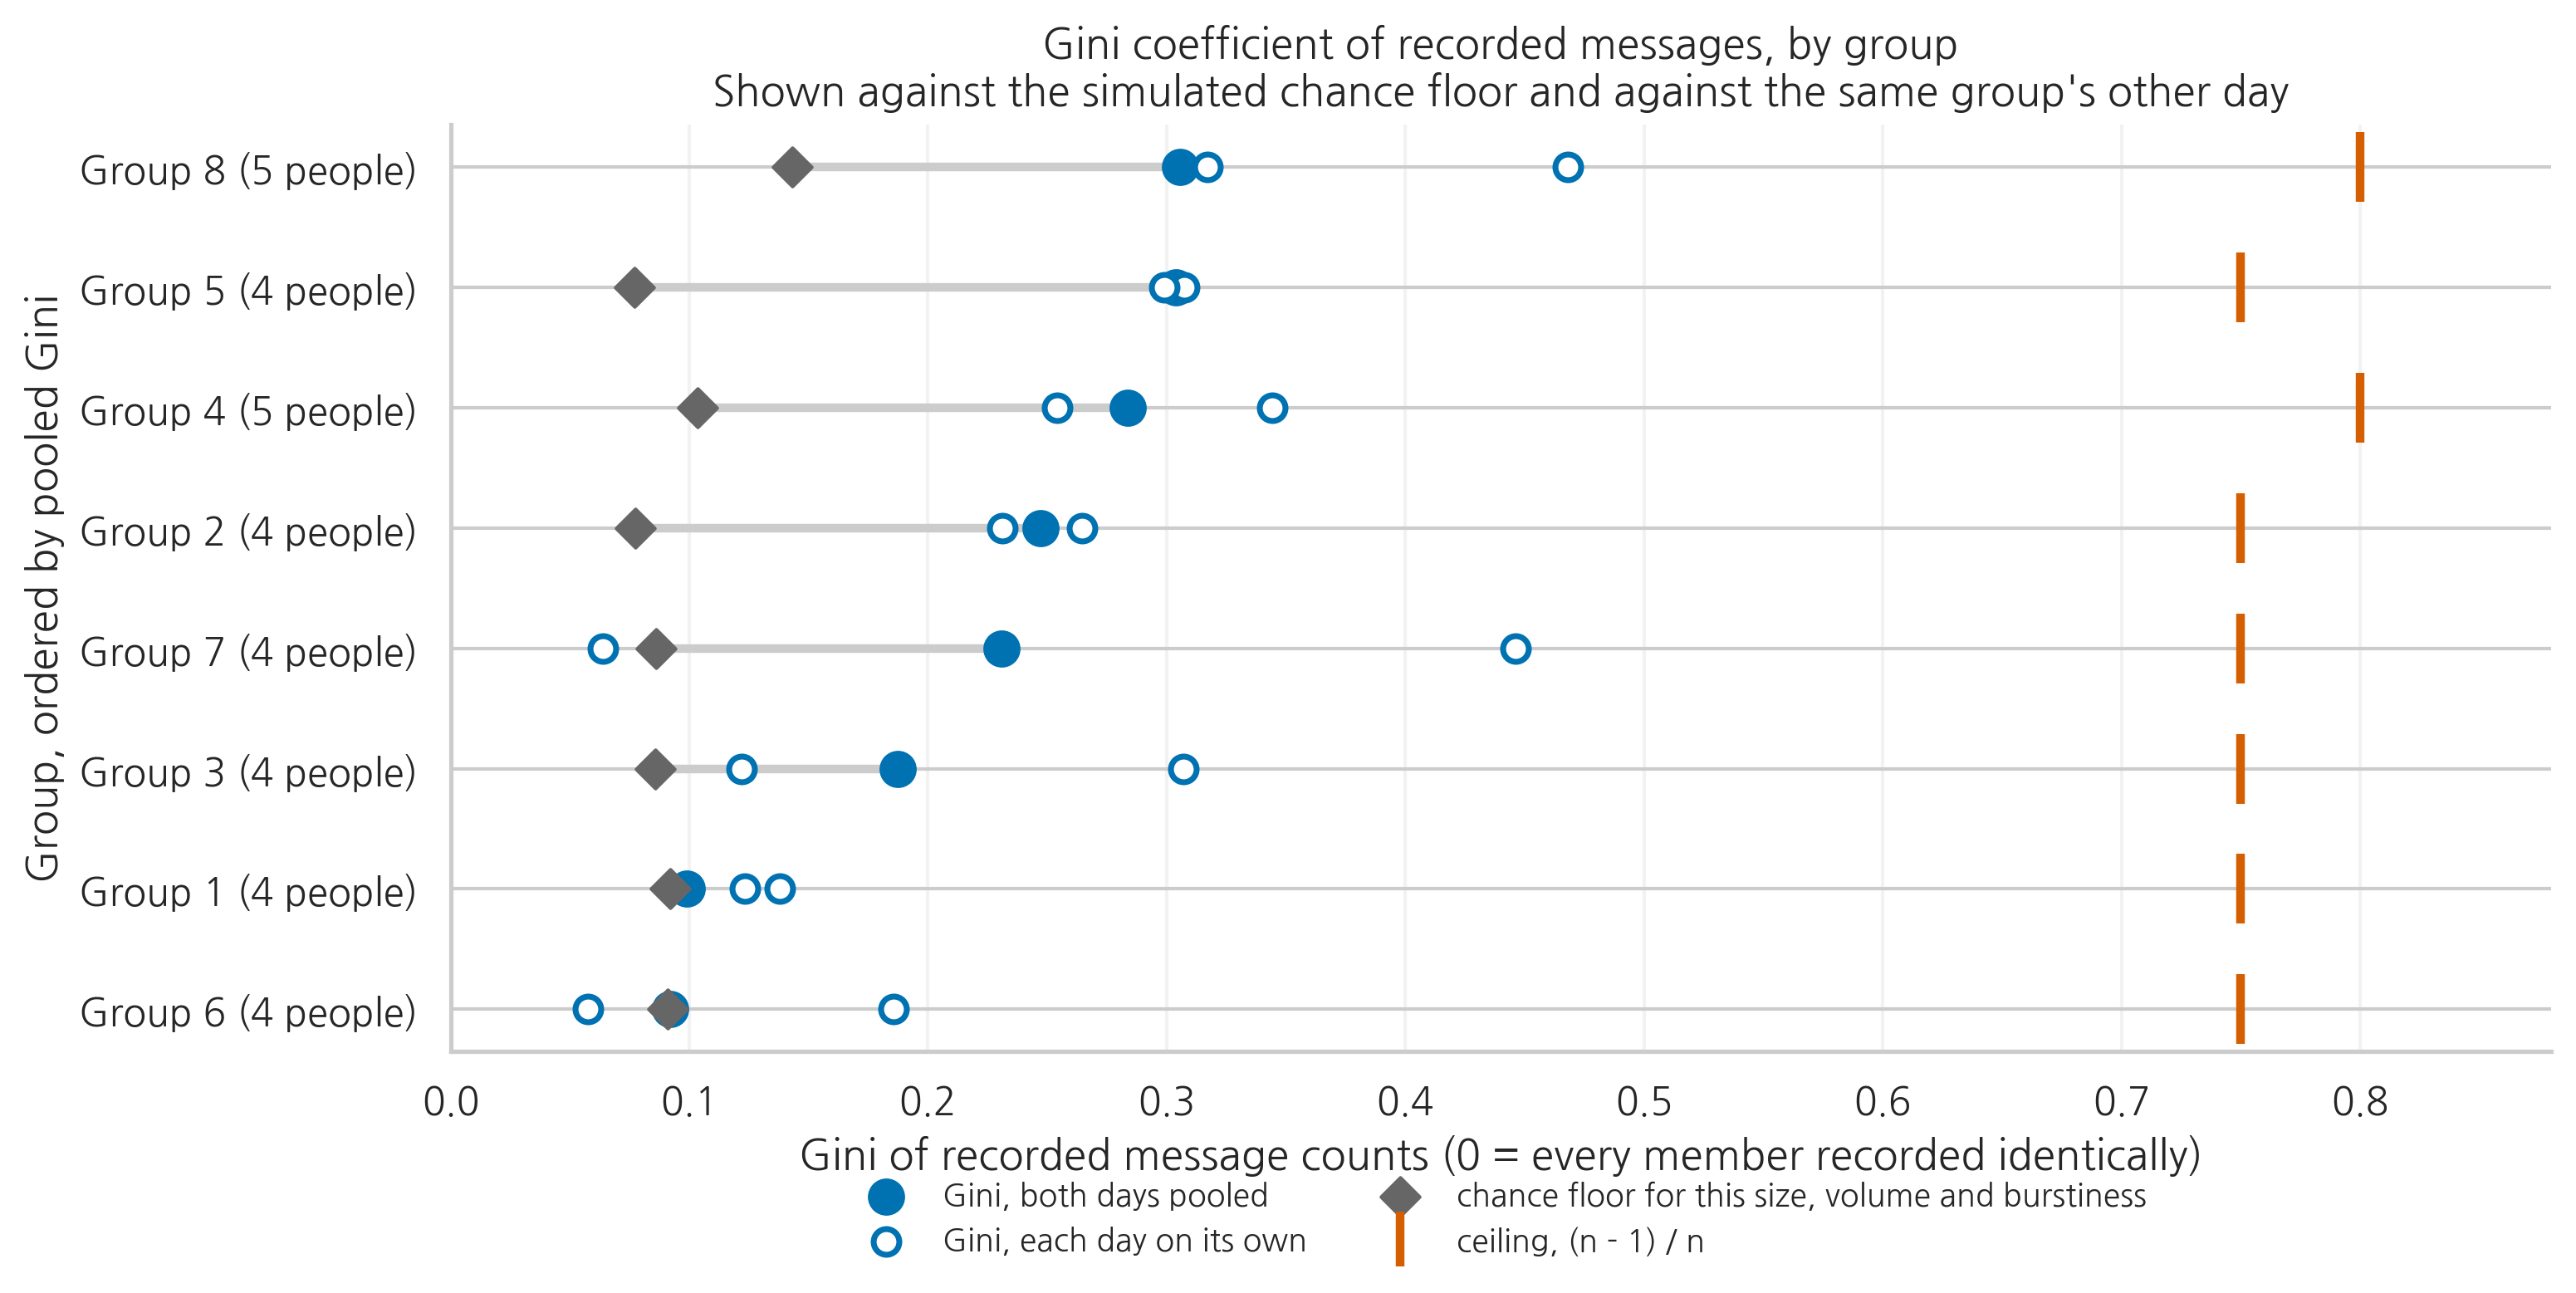

GINI BY GROUP AND DAY
         min    max  swing
group                     
1      0.123  0.138  0.015
2      0.231  0.265  0.033
3      0.122  0.307  0.185
4      0.254  0.344  0.090
5      0.299  0.307  0.008
6      0.058  0.186  0.128
7      0.064  0.446  0.382
8      0.317  0.468  0.151

  widest day-to-day swing inside a single group: 0.382 (Group 7, 0.064 then 0.446)
  full spread across all eight groups, both days pooled: 0.214
  groups whose own two days differ by more than that whole spread: 1


In [4]:
fig, ax = plt.subplots(figsize=(10.5, 5.4))
gs = groups.sort_values("gini").reset_index(drop=True)
for i, r in gs.iterrows():
    ax.plot([r.chance_mean, r.gini], [i, i], color="#cccccc", linewidth=2.5, zorder=1)
    days = sess[sess.group == r.group]
    ax.scatter(days.gini, [i] * len(days), s=55, facecolors="white",
               edgecolors=OKABE["blue"], linewidths=1.7, zorder=5)
    ax.scatter([r.gini], [i], s=95, color=OKABE["blue"], zorder=4)
    ax.scatter([r.chance_mean], [i], s=62, marker="D", color=OKABE["grey"], zorder=4)
    ax.plot([r.ceiling], [i], marker="|", markersize=20, markeredgewidth=2.5,
            color=OKABE["red"], zorder=4)
ax.scatter([], [], s=95, color=OKABE["blue"], label="Gini, both days pooled")
ax.scatter([], [], s=55, facecolors="white", edgecolors=OKABE["blue"], linewidths=1.7,
           label="Gini, each day on its own")
ax.scatter([], [], s=62, marker="D", color=OKABE["grey"],
           label="chance floor for this size, volume and burstiness")
ax.plot([], [], marker="|", linestyle="none", markersize=16, markeredgewidth=2.5,
        color=OKABE["red"], label="ceiling, (n - 1) / n")
ax.set_yticks(range(len(gs)))
ax.set_yticklabels([f"Group {int(r.group)} ({int(r.members)} people)" for _, r in gs.iterrows()])
ax.set_xlim(0, 0.88)
ax.set_xlabel("Gini of recorded message counts (0 = every member recorded identically)")
ax.set_ylabel("Group, ordered by pooled Gini")
ax.set_title("Gini coefficient of recorded messages, by group\n"
             "Shown against the simulated chance floor and against the same group's other day")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=2, frameon=False, fontsize=9)
ax.grid(axis="x", alpha=0.25)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

swing = sess.groupby("group").gini.agg(["min", "max"])
swing["swing"] = swing["max"] - swing["min"]
between = groups.gini.max() - groups.gini.min()
print("GINI BY GROUP AND DAY")
print("=" * 74)
print(swing.round(3).to_string())
print()
print(f"  widest day-to-day swing inside a single group: {swing.swing.max():.3f} "
      f"(Group {swing.swing.idxmax()}, {swing.loc[swing.swing.idxmax(), 'min']:.3f} then "
      f"{swing.loc[swing.swing.idxmax(), 'max']:.3f})")
print(f"  full spread across all eight groups, both days pooled: {between:.3f}")
print(f"  groups whose own two days differ by more than that whole spread: "
      f"{int((swing.swing > between).sum())}")

**Takeaway**

- Every group sits above its own chance floor, so the unevenness is not an artifact of how few messages were sent.
- The floor differs by group, because it depends on group size and message count. A single threshold applied to all eight would be wrong for the smaller logs.
- The two days of one group differ from each other by about as much as groups differ from one another.

## 3. Definitions of a contribution

Section 1 counted messages. A message can be one word or forty. `MEASURE` below switches the unit between messages, words and characters.

Run it at each of the three settings.

In [5]:
# Options: "messages", "characters", "words".
MEASURE = "characters"

chat["chars"] = chat["message"].astype(str).str.len()
chat["words"] = chat["message"].astype(str).str.split().str.len()

if MEASURE == "messages":
    contrib = chat.groupby(["Group", "authorid"]).size()
elif MEASURE == "characters":
    contrib = chat.groupby(["Group", "authorid"])["chars"].sum()
elif MEASURE == "words":
    contrib = chat.groupby(["Group", "authorid"])["words"].sum()
else:
    raise ValueError("MEASURE must be 'messages', 'characters' or 'words'")

alt = contrib.groupby(level=0).apply(lambda s: gini(s.values))
compare = pd.DataFrame({"gini_messages": groups.set_index("group").gini,
                        f"gini_{MEASURE}": alt})
compare["rank_messages"] = compare["gini_messages"].rank()
compare[f"rank_{MEASURE}"] = compare[f"gini_{MEASURE}"].rank()
rho = stats.spearmanr(compare["gini_messages"], compare[f"gini_{MEASURE}"]).statistic

print(f"GINI IN {MEASURE.upper()} AGAINST GINI IN MESSAGES")
print("=" * 74)
print(compare.round(3).to_string())
print()
print(f"  Spearman between the two rankings: {rho:+.3f}")
print(f"  messages that are two words or fewer: {100 * (chat.words <= 2).mean():.1f}%")
print(f"  median message length: {chat.chars.median():.0f} characters, "
      f"longest {chat.chars.max()}")
print(f"  total across the file: {int(chat.chars.sum())} characters, {int(chat.words.sum())} words")

print()
print("  the same comparison for all three units:")
for other, column in (("messages", None), ("characters", "chars"), ("words", "words")):
    series = (chat.groupby(["Group", "authorid"]).size() if column is None
              else chat.groupby(["Group", "authorid"])[column].sum())
    gini_other = series.groupby(level=0).apply(lambda s: gini(s.values))
    rho_other = stats.spearmanr(groups.set_index("group").gini, gini_other).statistic
    print(f"    {other:>10} against messages: Spearman {rho_other:+.3f}")

GINI IN CHARACTERS AGAINST GINI IN MESSAGES
   gini_messages  gini_characters  rank_messages  rank_characters
1          0.099            0.093            2.0              1.0
2          0.247            0.248            5.0              6.0
3          0.188            0.195            3.0              3.0
4          0.284            0.246            6.0              5.0
5          0.304            0.288            7.0              8.0
6          0.092            0.123            1.0              2.0
7          0.231            0.208            4.0              4.0
8          0.306            0.268            8.0              7.0

  Spearman between the two rankings: +0.929
  messages that are two words or fewer: 25.5%
  median message length: 25 characters, longest 228
  total across the file: 41684 characters, 8410 words

  the same comparison for all three units:
      messages against messages: Spearman +1.000
    characters against messages: Spearman +0.929
         words against 

**Takeaway**

- The ordering of groups is not stable across the three definitions. A group that looks balanced by message count can be unbalanced by words.
- Each definition encodes an assumption about what contributing means. Counting messages treats a one-word acknowledgment and a worked proposal as equal.
- The analyst chooses the unit before any group is compared. The data do not determine the choice.

## 4. Comparison across settings and channels

One quantity, the share held by the most active member expressed as a multiple of an even split, is computed in two settings and three channels: chat messages among four or five undergraduates, interface actions between two children, and speech between two children.

In [6]:
children  = pd.read_csv(f"{BASE}/justhink/per_participant.csv")
teams_out = pd.read_csv(f"{BASE}/justhink/pehri_team_outcomes.csv")

pair = children.pivot(index="team_no", columns="who")


def dyad_gini(a, b):
    """Gini for a team of two. Equals |a - b| / (2 (a + b)); its ceiling is 0.5."""
    if pd.isna(a) or pd.isna(b) or (a + b) <= 0:
        return np.nan
    return abs(a - b) / (2.0 * (a + b))


just = pd.DataFrame({
    "team": pair.index,
    "actions_total": pair[("actions", "A")] + pair[("actions", "B")],
    "turns_total": pair[("turns", "A")] + pair[("turns", "B")],
    "gini_actions": [dyad_gini(a, b) for a, b in zip(pair[("actions", "A")], pair[("actions", "B")])],
    "gini_speech": [dyad_gini(a, b) for a, b in zip(pair[("speech_secs", "A")], pair[("speech_secs", "B")])],
    "mean_gain": (pair[("gain", "A")] + pair[("gain", "B")]) / 2.0,
}).reset_index(drop=True)
# For a dyad, the busiest share as a multiple of an even split is exactly 1 + 2 * Gini.
just["top_x_even_actions"] = 1 + 2 * just["gini_actions"]
just["top_x_even_speech"] = 1 + 2 * just["gini_speech"]

merged = just.merge(teams_out[["team", "last_error", "T_LG_absolute"]], on="team", how="left")

print("SECOND SETTING: JUSThink")
print("=" * 74)
print(f"  children                          : {len(children)}")
print(f"  teams                             : {children.team_no.nunique()}, "
      f"every one of them exactly {children.groupby('team_no').size().unique()[0]} children")
print(f"  children with speech transcribed  : {int(children.speech_secs.notna().sum())} "
      f"({int(merged.gini_speech.notna().sum())} teams)")
print(f"  teams with a learning outcome row : {int(merged.T_LG_absolute.notna().sum())}")
print(f"  teams with speech AND an outcome  : "
      f"{int(merged.dropna(subset=['gini_speech', 'T_LG_absolute']).shape[0])}")
missing_teams = sorted(set(children.team_no) - set(teams_out.team.astype(int)))
print(f"  teams with no outcome row         : {missing_teams}")
print("  The dataset does not document why those rows are absent.")
print()
print("CONSISTENCY CHECK BETWEEN THE TWO FILES")
print("=" * 74)
chk = merged.dropna(subset=["T_LG_absolute"])
print("  T_LG_absolute should equal the pair's mean test change divided by 10.")
print(f"  largest disagreement across {len(chk)} teams: "
      f"{(chk.mean_gain / 10 - chk.T_LG_absolute).abs().max():.6f}")
print("  The two agree exactly, so the derived column is defined as expected.")
print()
print("BASE RATES")
print("=" * 74)
print(f"  pre-test mean {children.score_pre.mean():.2f} of 10, "
      f"post-test mean {children.score_post.mean():.2f}")
print(f"  teams whose pair average rose: {int((merged.mean_gain > 0).sum())}, "
      f"unchanged: {int((merged.mean_gain == 0).sum())}, "
      f"fell: {int((merged.mean_gain < 0).sum())}, out of {len(merged)}")
print("  Pair means changed little on a ten-point scale, so any correlate of learning gain")
print("  in this dataset describes a small and coarsely measured difference.")
print()
print(f"  ceiling on the Gini for a team of two: {(2 - 1) / 2:.2f}")
print(f"  interface actions, {int(just.gini_actions.notna().sum())} teams: Gini "
      f"{just.gini_actions.min():.3f} to {just.gini_actions.max():.3f}, "
      f"mean {just.gini_actions.mean():.3f}")
sp = just.dropna(subset=["gini_speech"])
print(f"  speech seconds,    {len(sp)} teams: Gini "
      f"{sp.gini_speech.min():.3f} to {sp.gini_speech.max():.3f}, mean {sp.gini_speech.mean():.3f}")
even = just[just.gini_actions == 0]
print(f"  teams whose two children have identical action counts: {len(even)}, "
      f"team {even.team.tolist()}, {even.actions_total.astype(int).tolist()} actions")

SECOND SETTING: JUSThink
  children                          : 78
  teams                             : 39, every one of them exactly 2 children
  children with speech transcribed  : 20 (10 teams)
  teams with a learning outcome row : 34
  teams with speech AND an outcome  : 9
  teams with no outcome row         : [11, 33, 34, 35, 36]
  The dataset does not document why those rows are absent.

CONSISTENCY CHECK BETWEEN THE TWO FILES
  T_LG_absolute should equal the pair's mean test change divided by 10.
  largest disagreement across 34 teams: 0.000000
  The two agree exactly, so the derived column is defined as expected.

BASE RATES
  pre-test mean 5.85 of 10, post-test mean 5.95
  teams whose pair average rose: 17, unchanged: 8, fell: 14, out of 39
  Pair means changed little on a ten-point scale, so any correlate of learning gain
  in this dataset describes a small and coarsely measured difference.

  ceiling on the Gini for a team of two: 0.50
  interface actions, 39 teams: Gini 0.0

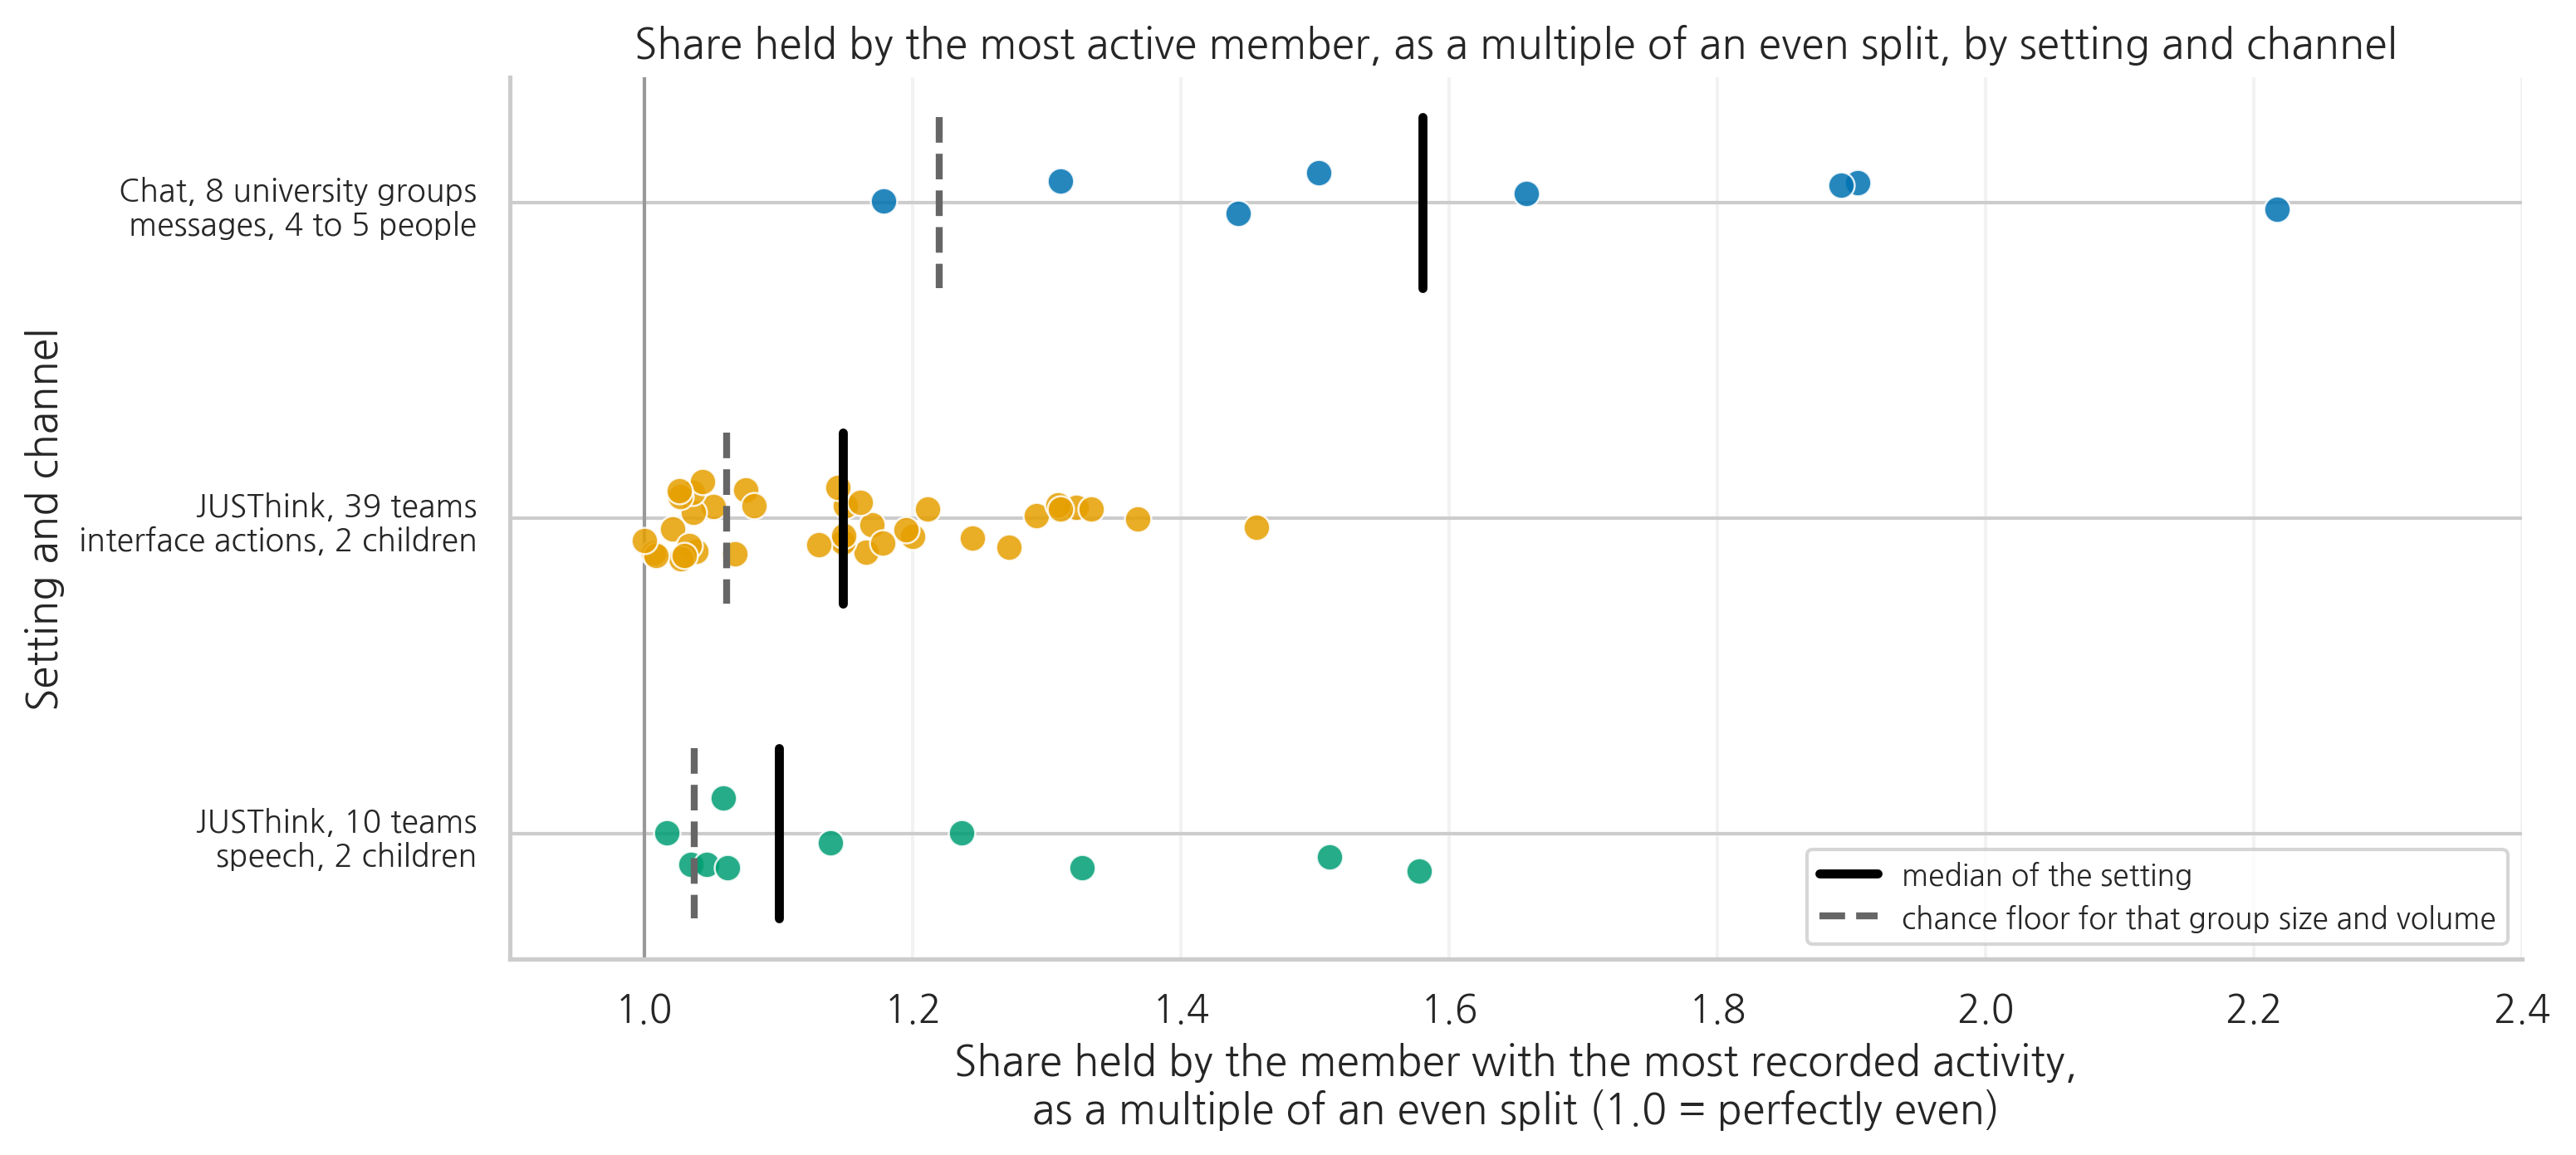

  Chat, 8 university groups    n=  8   range 1.18 to 2.22   median 1.58   chance floor 1.22
  JUSThink, 39 teams           n= 39   range 1.00 to 1.46   median 1.15   chance floor 1.06
  JUSThink, 10 teams           n= 10   range 1.02 to 1.58   median 1.10   chance floor 1.04


In [7]:
def chance_top_x_even(n_members, n_units, draws=4000, seed=8100):
    """Chance level for the busiest share as a multiple of an even split.

    Units are drawn as independent events. The JUSThink files carry no sequence, so
    run structure cannot be preserved for those two channels. Interface clicks and
    speaking turns are also likely to occur in runs, which makes these two floors
    lower bounds.
    """
    rng = np.random.default_rng(seed)
    sim = rng.multinomial(int(n_units), np.repeat(1.0 / n_members, n_members), size=draws)
    return float((sim.max(axis=1) / n_units * n_members).mean())


def chance_top_x_even_bursty(n_members, runs, draws=4000, seed=8100):
    """The chat version, with run structure preserved, as in section 2."""
    rng = np.random.default_rng(seed)
    runs = np.asarray(runs)
    n_turns = len(runs)
    who = rng.integers(0, n_members, size=(draws, n_turns))
    lens = rng.choice(runs, size=(draws, n_turns), replace=True)
    sim = np.empty((draws, n_members), dtype=float)
    for m in range(n_members):
        sim[:, m] = np.where(who == m, lens, 0).sum(axis=1)
    tot = sim.sum(axis=1)
    return float((sim.max(axis=1) / tot * n_members).mean())


chat_chance = np.median([chance_top_x_even_bursty(
    int(r.members), run_lengths(chat[chat["Group"] == r.group]))
    for _, r in groups.iterrows()])
act_chance = np.median([chance_top_x_even(2, t) for t in just.actions_total])
sp_chance = np.median([chance_top_x_even(2, t) for t in just.turns_total.dropna()])

strips = [
    ("Chat, 8 university groups\nmessages, 4 to 5 people",
     groups.top_share_x_even.values, chat_chance, OKABE["blue"]),
    ("JUSThink, 39 teams\ninterface actions, 2 children",
     just.top_x_even_actions.dropna().values, act_chance, OKABE["orange"]),
    ("JUSThink, 10 teams\nspeech, 2 children",
     just.top_x_even_speech.dropna().values, sp_chance, OKABE["green"]),
]

fig, ax = plt.subplots(figsize=(10.5, 4.8))
jit = np.random.default_rng(8100)
for i, (name, vals, ch, color) in enumerate(strips):
    ax.scatter(vals, i + jit.uniform(-0.13, 0.13, len(vals)), s=58, color=color,
               alpha=0.85, edgecolors="white", linewidths=0.6, zorder=3)
    ax.plot([np.median(vals)] * 2, [i - 0.27, i + 0.27], color="black", linewidth=2.6, zorder=4)
    ax.plot([ch] * 2, [i - 0.27, i + 0.27], color=OKABE["grey"], linewidth=2.0,
            linestyle="--", zorder=4)
ax.plot([], [], color="black", linewidth=2.6, label="median of the setting")
ax.plot([], [], color=OKABE["grey"], linewidth=2.0, linestyle="--",
        label="chance floor for that group size and volume")
ax.axvline(1.0, color="#999999", linewidth=1.0)
ax.set_yticks(range(len(strips)))
ax.set_yticklabels([s[0] for s in strips], fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0.9, 2.4)
ax.set_xlabel("Share held by the member with the most recorded activity,\n"
              "as a multiple of an even split (1.0 = perfectly even)")
ax.set_ylabel("Setting and channel")
ax.set_title("Share held by the most active member, as a multiple of an even split, by setting and channel")
ax.legend(loc="lower right", frameon=True, fontsize=8.5)
ax.grid(axis="x", alpha=0.25)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

for name, vals, ch, _ in strips:
    print(f"  {name.splitlines()[0]:<28} n={len(vals):>3}   "
          f"range {vals.min():.2f} to {vals.max():.2f}   median {np.median(vals):.2f}   "
          f"chance floor {ch:.2f}")

**Takeaway**

- The chat groups are far more uneven than the pairs, and the pairs sit close to their floor. Group size changes the range the measure can register.
- Speech and interface actions disagree about the same pairs, so the channel chosen determines who is recorded as the larger contributor.
- A threshold calibrated in one setting does not transfer to another, even when the measure is defined identically.

## 5. Teacher-facing design

Chen and Teasley (2022) distinguish analytics that describe collaboration from analytics intended to support it. Martinez-Maldonado and colleagues (2019) set out the dilemmas that arise when such data reaches a teacher during an activity rather than a researcher afterward.

In the cell below: what you would put on a teacher's screen from this data, and what you would refuse to put there.

In [8]:
PUT_ON_THE_SCREEN = """
"""

REFUSE_TO_SHOW = """
"""

for name, text in [("On the screen", PUT_ON_THE_SCREEN), ("Refused", REFUSE_TO_SHOW)]:
    print(name.upper()); print(text.strip() or "  [not yet written]"); print()

ON THE SCREEN
  [not yet written]

REFUSED
  [not yet written]



1. Every group is above its chance floor. What could a teacher do with that, and when in a course would it have to arrive?
2. The ordering changes with the measure. Which definition would you defend to the group whose position it lowers?
3. What happened in these eight groups that none of these measures can represent?

---

## Research brainstorming

For your own project. Not graded.

**1. What are you interested in?** Name the setting and the people.

**2. What is your research question?**

**3. Which of this semester's approaches could add a dimension to it?** For the ones you pick, say what it would make visible and what it would require you to collect.

| Week | Approach |
|---|---|
| 2 | Theoretical lenses for reading trace data |
| 3 | Responsible and human-centered analytics |
| 4 | Teacher-facing and student-facing dashboards |
| 5 | Text analytics and natural language processing |
| 6 | Multimodal analytics |
| 7 | Traces of self-regulated learning |
| 8 | Network analysis, and temporal analysis |
| 9 | Collaboration analytics |
| 10 | Game analytics, and emotional analytics |
| 11 | Designing and co-designing analytics systems |

In [9]:
INTEREST = """
"""

RESEARCH_QUESTION = """
"""

APPROACHES = """
"""

for name, text in [("What I am interested in", INTEREST),
                   ("My research question", RESEARCH_QUESTION),
                   ("Approaches that could add a dimension", APPROACHES)]:
    print(name.upper())
    print(text.strip() or "  [not yet written]")
    print()

WHAT I AM INTERESTED IN
  [not yet written]

MY RESEARCH QUESTION
  [not yet written]

APPROACHES THAT COULD ADD A DIMENSION
  [not yet written]

